<a href="https://colab.research.google.com/github/chaitraN-sys/Data-Visualization-Lab_Prgs/blob/main/Data_Visualization_Lab_prgs.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

total dataset size (545, 13)
Missing values:
 price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64
Duplicates: 0


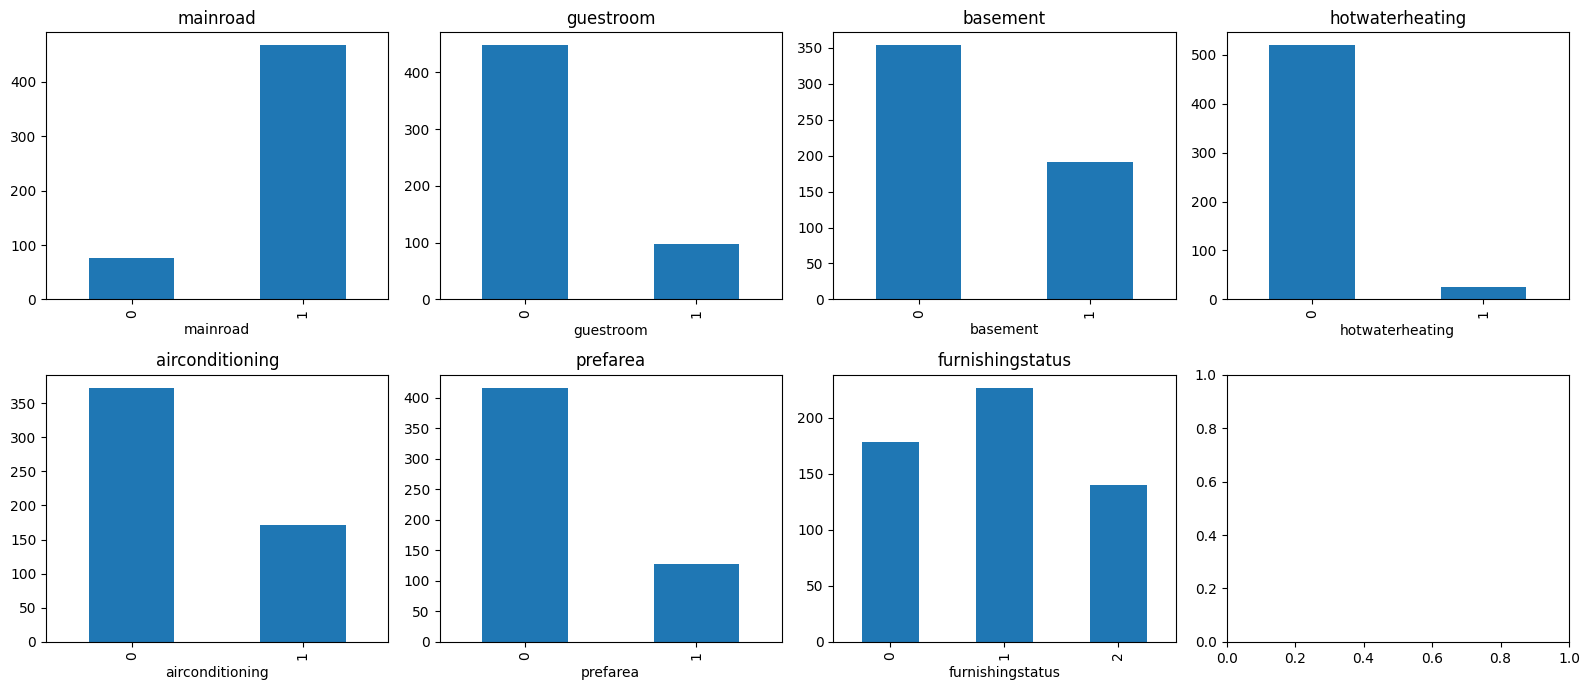

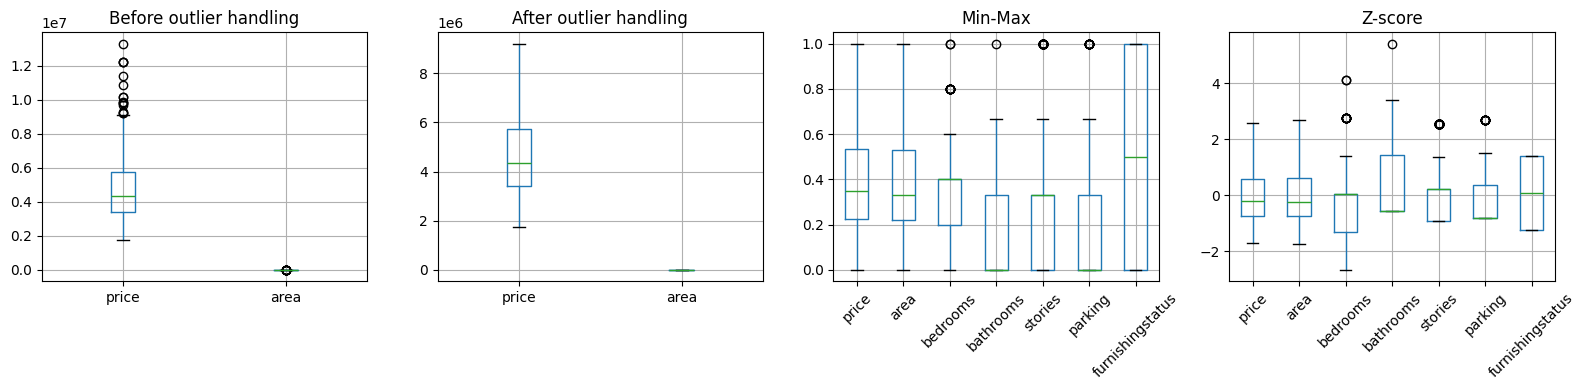

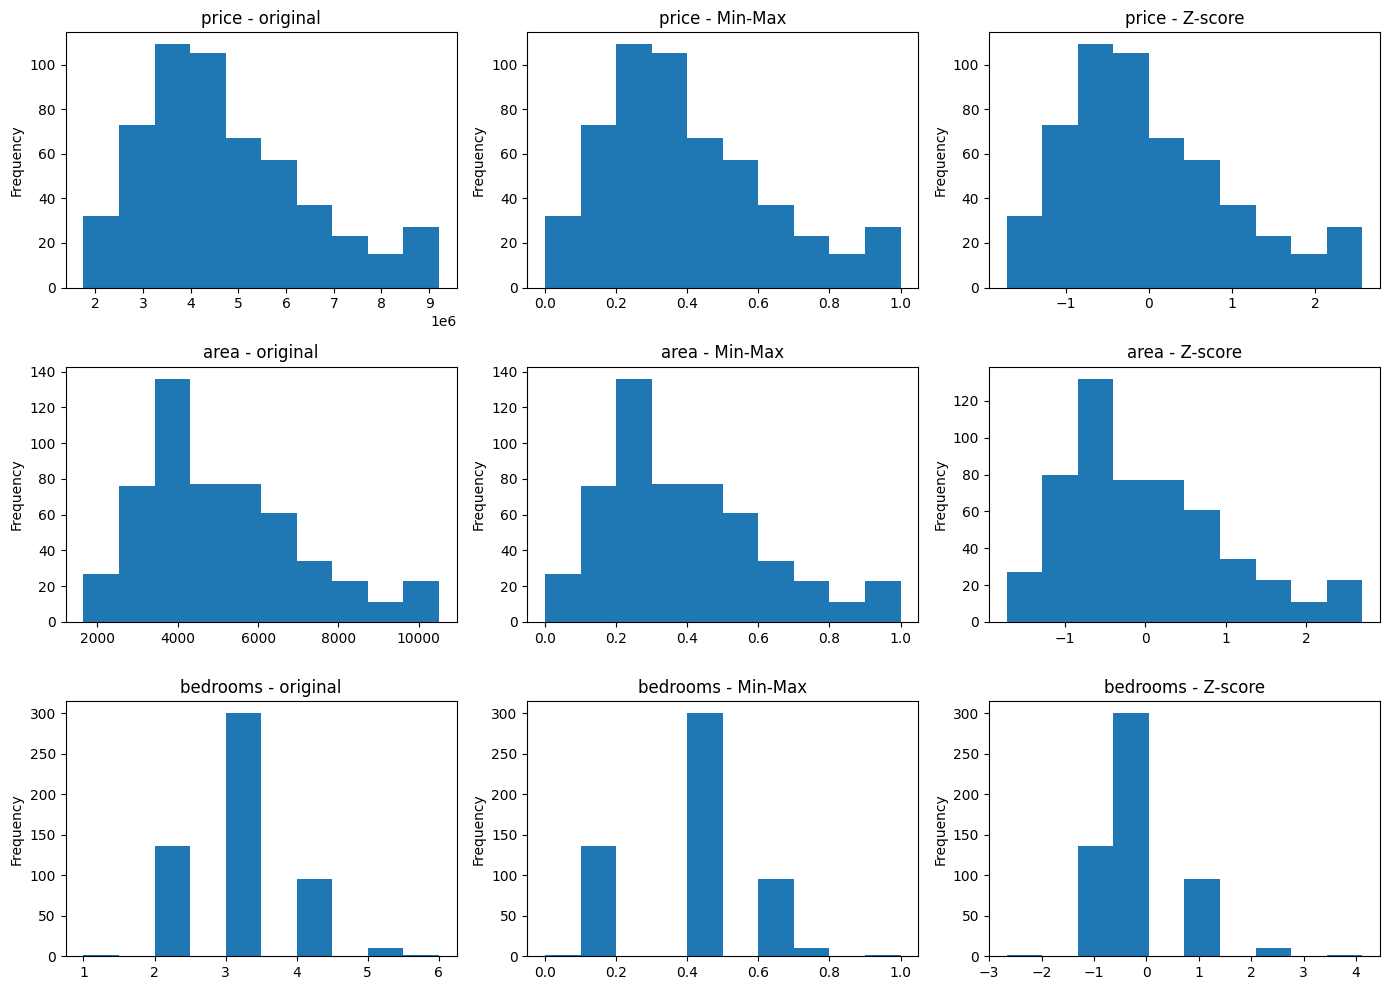

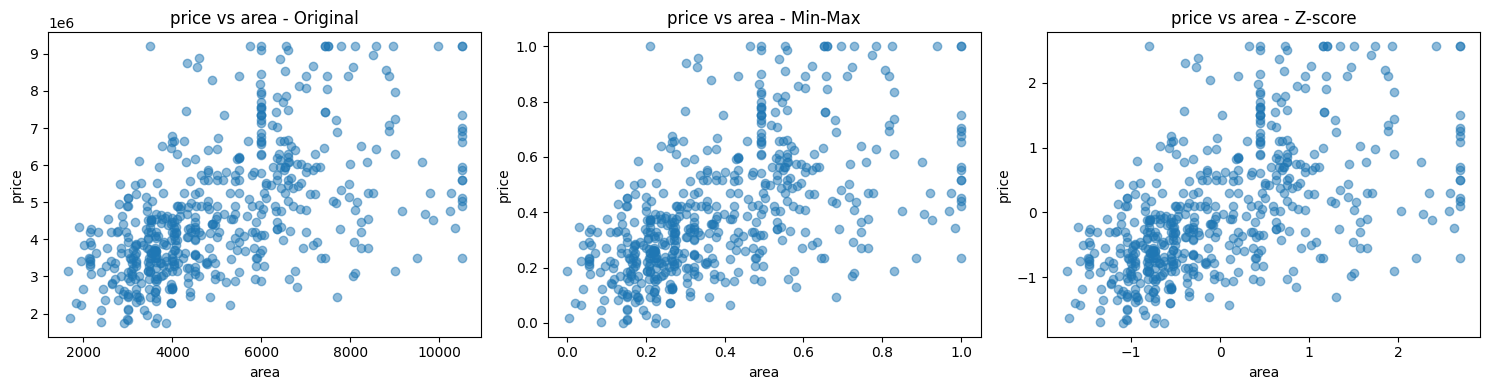

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# ---------- 1. Load ----------
df = pd.read_csv("/content/Housing.csv")          # change the path if needed
print("total dataset size",df.shape)

continuous = ["price", "area"]
discrete = ["bedrooms", "bathrooms", "stories", "parking"]
ordinal = ["furnishingstatus"]
nominal = ["mainroad", "guestroom", "basement", "hotwaterheating", "airconditioning", "prefarea"]

# ---------- 2. Missing values ----------
print("Missing values:\n", df.isnull().sum())
for col in df.columns:
    if pd.api.types.is_numeric_dtype(df[col]):
        df[col] = df[col].fillna(df[col].median())    # numbers -> median
    else:
        df[col] = df[col].fillna(df[col].mode()[0])   # text    -> mode

# ---------- 3. Duplicates ----------
print("Duplicates:", df.duplicated().sum())
df = df.drop_duplicates()

# ---------- 4. Outliers (IQR rule, cap the values) ----------
before_outliers = df[continuous].copy()
for col in continuous:
    q1, q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    iqr = q3 - q1
    df[col] = df[col].clip(q1 - 1.5 * iqr, q3 + 1.5 * iqr)

# ---------- 5. Encode categorical columns ----------
df["furnishingstatus"] = df["furnishingstatus"].map(
    {"unfurnished": 0, "semi-furnished": 1, "furnished": 2})      # ordinal
for col in nominal:
    df[col] = df[col].map({"no": 0, "yes": 1})                    # nominal (yes/no)

# ---------- 6. Scaling ----------
cols = continuous + discrete + ordinal
original = df.copy()

minmax = df.copy()
minmax[cols] = MinMaxScaler().fit_transform(df[cols])       # values between 0 and 1

zscore = df.copy()
zscore[cols] = StandardScaler().fit_transform(df[cols])     # mean 0, std 1

original.to_csv("housing_cleaned.csv", index=False)
minmax.to_csv("housing_minmax.csv", index=False)
zscore.to_csv("housing_zscore.csv", index=False)

# ---------- 7. Bar plots ----------
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), nominal + ordinal):
    original[col].value_counts().sort_index().plot(kind="bar", ax=ax, title=col)
plt.tight_layout()
plt.savefig("bar_plots.png")

# ---------- 8. Box plots (outliers before vs after) ----------
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
before_outliers.boxplot(ax=axes[0]); axes[0].set_title("Before outlier handling")
original[continuous].boxplot(ax=axes[1]); axes[1].set_title("After outlier handling")
minmax[cols].boxplot(ax=axes[2], rot=45); axes[2].set_title("Min-Max")
zscore[cols].boxplot(ax=axes[3], rot=45); axes[3].set_title("Z-score")
plt.tight_layout()
plt.savefig("box_plots.png")

# ---------- 9. Histograms: before vs after normalization ----------
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for i, col in enumerate(["price", "area", "bedrooms"]):
    original[col].plot(kind="hist", ax=axes[i, 0], title=f"{col} - original")
    minmax[col].plot(kind="hist", ax=axes[i, 1], title=f"{col} - Min-Max")
    zscore[col].plot(kind="hist", ax=axes[i, 2], title=f"{col} - Z-score")
plt.tight_layout()
plt.savefig("histograms.png")

# ---------- 10. Scatter plots: before vs after normalization ----------
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, data, name in zip(axes, [original, minmax, zscore], ["Original", "Min-Max", "Z-score"]):
    ax.scatter(data["area"], data["price"], alpha=0.5)
    ax.set_title(f"price vs area - {name}")
    ax.set_xlabel("area")
    ax.set_ylabel("price")
plt.tight_layout()
plt.savefig("scatter_plots.png")

plt.show()